# Temporal Event Graph ↔ TQP 파일럿 (Colab)

**목표:** 동일한 TQP를 기존 Interval 실행기와 Temporal Event Graph(TEG) 실행기에 입력하여 결과가 완전히 일치하는지 점검합니다. `THEN` 방향, `WHILE` 대칭성, `PARTIAL/UNCERTAIN` 제외 규칙을 확인하고 그래프 구축시간·질의 실행시간을 측정합니다.

- 처음 5개 셀은 합성 자료만 사용합니다. GPU 및 AV2 다운로드는 필요하지 않습니다.
- 마지막 셀은 `RUN_REAL_AV2=True`를 직접 설정한 뒤 사용자가 준비한 AV2 Feather 파일을 읽습니다.
- **주의:** 이 파일럿에는 Qwen2.5 추론이나 B2 직접 코드 생성이 포함되지 않습니다. H1 검증이 아니라 TQP의 검색 백엔드 검증입니다.
- 사건 검출 임계값은 사용자의 v4 설계 초안을 따라 만든 예비 구현입니다. RefAV와 동일한 검출기라고 주장하지 않습니다.


In [1]:
%pip install -q numpy pandas scipy matplotlib pyarrow pytest

In [2]:
%%writefile teg_pilot.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""Deterministic pilot for Temporal Query Plan (TQP) ↔ Temporal Event Graph.

No LLM, no GraphRAG and no sensor perception. The optional AV2 input requires
only annotations.feather and city_SE3_egovehicle.feather per log.
"""
from __future__ import annotations

import argparse
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
import json
import math
from pathlib import Path
import time
import tracemalloc
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation

VERSION = "0.1.0"
EVENT_TYPES = ("TURN", "DECELERATE", "ACCELERATE", "STOP")
VEHICLE_CATEGORIES = {
    "REGULAR_VEHICLE", "LARGE_VEHICLE", "BUS", "BOX_TRUCK",
    "TRUCK", "TRUCK_CAB", "SCHOOL_BUS", "ARTICULATED_BUS"
}

@dataclass(frozen=True)
class Event:
    event_id: str
    log_id: str
    track_id: str
    type: str
    start: float
    end: float
    clipped: bool = False
    # clipped means event threshold remains active at an observation boundary.

    def __post_init__(self) -> None:
        if self.type not in EVENT_TYPES:
            raise ValueError(f"Unknown event type: {self.type}")
        if not (np.isfinite(self.start) and np.isfinite(self.end) and self.end > self.start):
            raise ValueError("Event must have a finite positive duration")

    @property
    def track_key(self) -> Tuple[str, str]:
        return (self.log_id, self.track_id)

@dataclass(frozen=True)
class Query:
    first: str
    relation: str
    second: str

    def __post_init__(self) -> None:
        if self.first not in EVENT_TYPES or self.second not in EVENT_TYPES:
            raise ValueError("Unsupported event type")
        if self.relation not in ("THEN", "WHILE"):
            raise ValueError("Unsupported relation")

    def to_tqp(self) -> dict:
        return {"events": {"e1": self.first, "e2": self.second},
                "relation": {"op": self.relation, "args": ["e1", "e2"]}}


def parse_tqp(plan: dict) -> Query:
    """Validate TQP without evaluating LLM-produced code."""
    if not isinstance(plan, dict) or set(plan) != {"events", "relation"}:
        raise ValueError("TQP must have only events and relation")
    events, relation = plan["events"], plan["relation"]
    if not isinstance(events, dict) or set(events) != {"e1", "e2"}:
        raise ValueError("Expected event slots e1 and e2")
    if not isinstance(relation, dict) or set(relation) != {"op", "args"}:
        raise ValueError("Expected relation op and args")
    args = relation["args"]
    if not isinstance(args, list) or sorted(args) != ["e1", "e2"]:
        raise ValueError("Relation args must be e1 and e2 once each")
    return Query(events[args[0]], relation["op"], events[args[1]])


def interval_relation(a: Event, b: Event, *, delta: float = 5.0,
                      overlap_threshold: float = 0.8) -> str:
    """Classify an ORDERED pair. Ambiguous pairs are not negatives.

    THEN: s_A < s_B and -0.5 <= s_B - e_A <= delta.
    WHILE: overlap > 0.5s and overlap / min(duration_A, duration_B) >= threshold.
    PARTIAL: 0.5s < overlap with insufficient overlap ratio.
    Other pairs: NONE. Boundary-clipped events: UNCERTAIN.
    """
    if a.event_id == b.event_id or a.track_key != b.track_key:
        return "NONE"
    if a.clipped or b.clipped:
        return "UNCERTAIN"
    overlap = max(0.0, min(a.end, b.end) - max(a.start, b.start))
    shorter = min(a.end - a.start, b.end - b.start)
    if overlap > 0.5:
        return "WHILE" if overlap / shorter >= overlap_threshold - 1e-12 else "PARTIAL"
    if a.start < b.start and -0.5 - 1e-12 <= b.start - a.end <= delta + 1e-12:
        return "THEN"
    return "NONE"


def group_by_track(events: Sequence[Event]) -> Dict[Tuple[str, str], List[Event]]:
    result: Dict[Tuple[str, str], List[Event]] = defaultdict(list)
    for event in events:
        result[event.track_key].append(event)
    return dict(result)


def interval_statuses(groups: Mapping[Tuple[str, str], Sequence[Event]], q: Query,
                      *, delta: float = 5.0, overlap_threshold: float = 0.8) -> dict:
    """One status per track: POSITIVE, PARTIAL, UNCERTAIN, NEGATIVE.

    Important: positive wins over any ambiguous candidate. If no positive,
    uncertain wins over partial; both statuses should be excluded from F1.
    """
    out = {}
    for key, events in groups.items():
        left = [e for e in events if e.type == q.first]
        right = [e for e in events if e.type == q.second]
        seen = set()
        amb = set()
        positive = False
        for a in left:
            for b in right:
                if a.event_id == b.event_id:
                    continue
                relation = interval_relation(a, b, delta=delta,
                                             overlap_threshold=overlap_threshold)
                if relation == q.relation:
                    positive = True
                    break
                if relation in ("PARTIAL", "UNCERTAIN"):
                    amb.add(relation)
            if positive:
                break
        out[key] = ("POSITIVE" if positive else
                    "UNCERTAIN" if "UNCERTAIN" in amb else
                    "PARTIAL" if "PARTIAL" in amb else "NEGATIVE")
    return out


class TemporalEventGraph:
    """Compact graph with typed relation edges and track-level query indices.

    Event IDs are nodes; relation records are directed edges. Symmetric WHILE
    is indexed in both directions. Candidate ambiguity is tracked separately.
    """
    def __init__(self, events: Sequence[Event], *, delta: float = 5.0,
                 overlap_threshold: float = 0.8,
                 track_universe: Optional[Iterable[Tuple[str, str]]] = None):
        self.delta = delta
        self.overlap_threshold = overlap_threshold
        self.nodes = {e.event_id: e for e in events}
        if len(self.nodes) != len(events):
            raise ValueError("Duplicate event_id")
        self.track_events = group_by_track(events)
        if track_universe is not None:
            for track_key in track_universe:
                self.track_events.setdefault(tuple(track_key), [])
        self.edge_index = defaultdict(set)  # (relation, left_type, right_type) -> (log,track)
        self.edges = []                      # (src_id, relation, dst_id)
        self.ambiguous = defaultdict(set)    # (left_type,right_type) -> (key,status)
        self.pair_count = 0
        for key, evs in self.track_events.items():
            for a in evs:
                for b in evs:
                    if a.event_id == b.event_id:
                        continue
                    self.pair_count += 1
                    r = interval_relation(a, b, delta=delta,
                                          overlap_threshold=overlap_threshold)
                    if r in ("THEN", "WHILE"):
                        self.edges.append((a.event_id, r, b.event_id))
                        self.edge_index[(r, a.type, b.type)].add(key)
                    elif r in ("PARTIAL", "UNCERTAIN"):
                        self.ambiguous[(a.type, b.type)].add((key, r))
        self.all_keys = set(self.track_events)

    def statuses(self, q: Query) -> dict:
        pos = self.edge_index.get((q.relation, q.first, q.second), set())
        ambiguities = defaultdict(set)
        for key, status in self.ambiguous.get((q.first, q.second), set()):
            ambiguities[key].add(status)
        return {key: ("POSITIVE" if key in pos else
                      "UNCERTAIN" if "UNCERTAIN" in ambiguities[key] else
                      "PARTIAL" if "PARTIAL" in ambiguities[key] else "NEGATIVE")
                for key in self.all_keys}

    def summary(self) -> dict:
        return {
            "event_nodes": len(self.nodes),
            "track_nodes": len(self.track_events),
            "typed_relation_edges": len(self.edges),
            "directed_candidate_pairs_evaluated": self.pair_count,
            "edges_by_type": dict(Counter(edge[1] for edge in self.edges)),
        }


def contiguous_runs(mask: np.ndarray) -> List[Tuple[int, int]]:
    padded = np.r_[False, np.asarray(mask, dtype=bool), False]
    starts = np.flatnonzero(np.diff(padded.astype(int)) == 1)
    ends = np.flatnonzero(np.diff(padded.astype(int)) == -1)
    return list(zip(starts.tolist(), ends.tolist()))


def extract_events(t: np.ndarray, x: np.ndarray, y: np.ndarray,
                   log_id: str, track_id: str) -> List[Event]:
    """Preliminary motion detector for ~10Hz AV2 track segments.

    No infilling across missing frames: segment at >0.25s gap. 1.1s
    Savitzky–Golay smoothing of global XY; same window on velocity. Treat
    threshold active at a segment boundary as clipped/uncertain. This is
    deliberately a pilot, not validated RefAV detector equivalence.
    """
    t = np.asarray(t, float); x = np.asarray(x, float); y = np.asarray(y, float)
    if len(t) < 11:
        return []
    order = np.argsort(t)
    t, x, y = t[order], x[order], y[order]
    result: List[Event] = []
    splitpoints = np.r_[0, np.flatnonzero(np.diff(t) > 0.25) + 1, len(t)]
    for sl, sr in zip(splitpoints[:-1], splitpoints[1:]):
        tt, xx, yy = t[sl:sr], x[sl:sr], y[sl:sr]
        if len(tt) < 11 or np.any(np.diff(tt) <= 0):
            continue
        dt = float(np.median(np.diff(tt)))
        if not 0.075 <= dt <= 0.125:  # 10Hz assumptions are explicit
            continue
        if np.max(np.hypot(xx - xx[0], yy - yy[0])) < 3.0:
            continue
        window = 11
        # SG derivatives are in units of seconds, using physical time step.
        vx = savgol_filter(xx, window, 2, deriv=1, delta=dt)
        vy = savgol_filter(yy, window, 2, deriv=1, delta=dt)
        speed = np.hypot(vx, vy)
        acceleration = savgol_filter(speed, window, 2, deriv=1, delta=dt)
        heading = np.unwrap(np.arctan2(vy, vx))
        yaw_rate = savgol_filter(heading, window, 2, deriv=1, delta=dt)
        travel = np.r_[0.0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        # Require motion for heading stability.
        masks = {
            "DECELERATE": acceleration <= -1.0,
            "ACCELERATE": acceleration >= 1.0,
            "STOP": speed < 0.5,
        }
        left_ids = [("TURN_L", yaw_rate >= np.deg2rad(5.0)),
                    ("TURN_R", yaw_rate <= -np.deg2rad(5.0))]
        for kind, mask in list(masks.items()) + left_ids:
            for a, b in contiguous_runs(mask):
                duration = (b-a)*dt
                if kind == "STOP":
                    valid = duration >= 1.0-1e-9
                elif kind in ("DECELERATE", "ACCELERATE"):
                    dv = speed[b-1] - speed[a]
                    valid = duration >= 0.5-1e-9 and ((dv <= -1.5) if kind == "DECELERATE" else (dv >= 1.5))
                else:
                    turn = abs(np.trapezoid(yaw_rate[a:b], dx=dt))
                    valid = (turn >= np.deg2rad(45.0) and
                             travel[b-1] - travel[a] >= 5.0 and
                             float(np.median(speed[a:b])) >= 1.0)
                if valid:
                    typ = "TURN" if kind.startswith("TURN") else kind
                    # end of the last active sample's 10Hz cell
                    first, last = float(tt[a]), float(tt[b-1]+dt)
                    result.append(Event(f"{log_id}:{track_id}:{len(result)}", log_id,
                                        track_id, typ, first, last,
                                        clipped=(a == 0 or b == len(tt))))
    return result


def synthetic_track(label: str, *, duration: float = 12.0, dt: float = 0.1) -> tuple:
    """Generate plausible kinematic vehicle paths: only for a software smoke test."""
    t = np.round(np.arange(0, duration + 1e-9, dt), 5)
    speed = np.full(t.shape, 10.0)
    yaw = np.zeros_like(t)
    if label == "before":
        decel, turn = (1., 3.), (5., 8.)
    elif label == "after":
        decel, turn = (5., 7.), (1., 4.)
    elif label == "while":
        decel, turn = (3.5, 5.7), (3., 6.)
    elif label == "partial":
        decel, turn = (2., 4.), (3.6, 6.6)
    elif label == "constant":
        decel, turn = None, None
    else:
        raise ValueError(label)
    if decel:
        for i in range(1, len(t)):
            if decel[0] <= t[i] < decel[1]:
                speed[i] = max(3.0, speed[i-1] - 3.0*dt)
            else:
                speed[i] = speed[i-1]
    if turn:
        for i in range(1, len(t)):
            yaw[i] = yaw[i-1] + (np.deg2rad(20) * dt if turn[0] <= t[i] < turn[1] else 0.0)
    vx, vy = speed*np.cos(yaw), speed*np.sin(yaw)
    x = np.r_[0., np.cumsum(vx[:-1]*dt)]
    y = np.r_[0., np.cumsum(vy[:-1]*dt)]
    return t, x, y


def synthetic_events() -> List[Event]:
    """Hand-coded exact event intervals used for deterministic relation tests."""
    rows = [
        ("before", "DECELERATE", 1, 3, False),
        ("before", "TURN", 5, 7, False),
        ("after", "TURN", 1, 3, False),
        ("after", "DECELERATE", 5, 7, False),
        ("while", "DECELERATE", 3.5, 5.5, False),
        ("while", "TURN", 3.0, 6.0, False),
        ("partial", "DECELERATE", 2, 5, False),
        ("partial", "TURN", 4, 7, False),
        ("edge", "DECELERATE", 0, 1.5, True),
        ("edge", "TURN", 3, 5, False),
        ("negative", "ACCELERATE", 2, 5, False),
    ]
    return [Event(f"synthetic:{track}:{i}", "synthetic", track, typ, float(s), float(e), clipped)
            for i, (track, typ, s, e, clipped) in enumerate(rows)]


def tracks_from_av2(log_folder: Path, *, tolerance_ms: float = 15., max_tracks: Optional[int] = None) -> Tuple[List[Event], dict, set]:
    """AV2 annotation cuboid centers (ego) → city coordinates by nearest ego pose.

    Nearest pose matching is bounded and reported; missing poses are dropped.
    This is *not* sensor detection. Only per-log Feather files are necessary.
    """
    anno_path = log_folder / "annotations.feather"
    pose_path = log_folder / "city_SE3_egovehicle.feather"
    if not (anno_path.is_file() and pose_path.is_file()):
        raise FileNotFoundError(f"Expected annotations.feather and city_SE3_egovehicle.feather in {log_folder}")
    cols_anno = ["timestamp_ns", "track_uuid", "category", "tx_m", "ty_m", "tz_m"]
    cols_pose = ["timestamp_ns", "qw", "qx", "qy", "qz", "tx_m", "ty_m", "tz_m"]
    ann = pd.read_feather(anno_path, columns=cols_anno)
    pose = pd.read_feather(pose_path, columns=cols_pose)
    ann = ann[ann.category.isin(VEHICLE_CATEGORIES)].copy()
    ann = ann.sort_values(["timestamp_ns", "track_uuid"]).drop_duplicates(["track_uuid", "timestamp_ns"])
    pose = pose.sort_values("timestamp_ns").drop_duplicates("timestamp_ns")
    if max_tracks:
        allowed = sorted(ann.track_uuid.astype(str).unique())[:max_tracks]
        ann = ann[ann.track_uuid.astype(str).isin(allowed)].copy()
    # Prefix pose columns to avoid mixing ego-local cuboid translations with world pose.
    pose = pose.rename(columns={c: f"pose_{c}" for c in cols_pose if c != "timestamp_ns"})
    pose = pose.rename(columns={"timestamp_ns": "pose_timestamp_ns"})
    joined = pd.merge_asof(
        ann.sort_values("timestamp_ns"),
        pose.sort_values("pose_timestamp_ns"),
        left_on="timestamp_ns", right_on="pose_timestamp_ns", direction="nearest",
        tolerance=int(tolerance_ms*1e6),
    )
    unmatched = int(joined.pose_timestamp_ns.isna().sum())
    joined = joined.dropna(subset=["pose_timestamp_ns"]).copy()
    if len(joined) == 0 or unmatched / max(len(ann),1) > 0.05:
        raise ValueError("Too many annotations lacked matching ego poses (>5%); check timing and tolerance")
    ego_points = joined[["tx_m", "ty_m", "tz_m"]].to_numpy(dtype=float)
    quat = joined[["pose_qx", "pose_qy", "pose_qz", "pose_qw"]].to_numpy(dtype=float)
    xyz_city = Rotation.from_quat(quat).apply(ego_points) + joined[["pose_tx_m", "pose_ty_m", "pose_tz_m"]].to_numpy(dtype=float)
    joined["cx_m"], joined["cy_m"] = xyz_city[:,0], xyz_city[:,1]
    log_id = log_folder.name
    result = []
    eligible = 0
    universe = set()
    # Each track split further at gaps within extract_events.
    for track_id, df in joined.groupby("track_uuid", sort=True):
        tt = (df.timestamp_ns.to_numpy(dtype=np.int64) - int(df.timestamp_ns.min())) / 1e9
        if len(tt) < 11 or np.ptp(tt) < 1.0:
            continue
        xx, yy = df.cx_m.to_numpy(), df.cy_m.to_numpy()
        if max(np.max(np.abs(xx-xx[0])), np.max(np.abs(yy-yy[0]))) < 2.13:
            # Conservative fast-reject: vehicle displacement must reach ~3m.
            continue
        eligible += 1
        universe.add((log_id, str(track_id)))
        result.extend(extract_events(tt, xx, yy, log_id, str(track_id)))
    info = {"log": log_id, "annotations_vehicle_rows": int(len(ann)),
            "annotations_without_nearby_pose": unmatched,
            "pose_match_rate": round(1.0 - unmatched/max(len(ann),1), 6),
            "vehicle_tracks": int(ann.track_uuid.nunique()),
            "eligible_moving_tracks": eligible,
            "detected_events": len(result),
            "max_pose_time_difference_ms": float(np.max(np.abs((joined.timestamp_ns - joined.pose_timestamp_ns) / 1e6)))}
    return result, info, universe


def default_queries() -> List[Query]:
    return [
        Query("DECELERATE", "THEN", "TURN"),
        Query("TURN", "THEN", "DECELERATE"),
        Query("DECELERATE", "WHILE", "TURN"),
        Query("TURN", "WHILE", "DECELERATE"),
        Query("DECELERATE", "THEN", "STOP"),
        Query("STOP", "THEN", "DECELERATE"),
        Query("DECELERATE", "THEN", "ACCELERATE"),
        Query("ACCELERATE", "THEN", "DECELERATE"),
        Query("ACCELERATE", "WHILE", "TURN"),
        Query("TURN", "THEN", "ACCELERATE"),
    ]


def run_comparison(events: Sequence[Event], queries: Sequence[Query], *, repeat: int = 300,
                   delta: float = 5., overlap_threshold: float = 0.8,
                   track_universe: Optional[Iterable[Tuple[str, str]]] = None) -> tuple:
    if not events:
        raise ValueError("No events: need at least one detected motion event; cannot benchmark")
    groups = group_by_track(events)
    if track_universe is not None:
        for track_key in track_universe:
            groups.setdefault(tuple(track_key), [])
    tracemalloc.start()
    start = time.perf_counter()
    graph = TemporalEventGraph(events, delta=delta, overlap_threshold=overlap_threshold,
                               track_universe=track_universe)
    graph_build_ms = (time.perf_counter()-start)*1000
    _, peak_graph_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    per_query = []
    for q in queries:
        expected = interval_statuses(groups, q, delta=delta, overlap_threshold=overlap_threshold)
        obtained = graph.statuses(q)
        different = [k for k in expected if expected[k] != obtained.get(k)]
        per_query.append({"query": f"{q.first} {q.relation} {q.second}",
                          "tqp": q.to_tqp(),
                          "equal": not different,
                          "mismatches": [[*k, expected[k], obtained.get(k)] for k in different],
                          "track_status_count": dict(Counter(expected.values())),
                          "positive_track_ids": [list(k) for k,s in expected.items() if s == "POSITIVE"][:20]})
    # timing includes the construction of a full per-track status map for both backends
    def timing(fn):
        st = time.perf_counter()
        for _ in range(repeat):
            for q in queries:
                fn(q)
        return (time.perf_counter()-st)*1000/(repeat*len(queries))
    interval_ms = timing(lambda q: interval_statuses(groups, q, delta=delta,
                                                       overlap_threshold=overlap_threshold))
    graph_ms = timing(graph.statuses)
    graph_info = graph.summary()
    saved = interval_ms - graph_ms
    estimated_break_even = (round(graph_build_ms / saved) if saved > 0 else None)
    report = {
        "version": VERSION,
        "assumptions": {"THEN_max_gap_seconds":delta,"THEN_overlap_tolerance_seconds":0.5,
                        "WHILE_min_overlap_seconds_strict":0.5,"WHILE_shorter_interval_ratio":overlap_threshold,
                        "backend": "Python adjacency/index, no Neo4j, no GraphRAG"},
        "event_count":len(events),
        "track_count":len(groups),
        "graph":graph_info,
        "graph_build_ms": round(graph_build_ms,3),
        "graph_build_peak_tracemalloc_kib": round(peak_graph_mem/1024,2),
        "mean_interval_query_ms": round(interval_ms,5),
        "mean_graph_query_ms": round(graph_ms,5),
        "estimated_break_even_query_count": estimated_break_even,
        "query_count":len(queries),
        "repeat_for_microbenchmark":repeat,
        "all_query_results_equal": all(x["equal"] for x in per_query),
        "per_query":per_query,
    }
    return report, graph


def write_graph_data(events: Sequence[Event], graph: TemporalEventGraph, out: Path) -> None:
    pd.DataFrame([asdict(e) for e in events]).to_csv(out / "event_nodes.csv", index=False)
    pd.DataFrame(graph.edges, columns=["source_event_id", "relation", "target_event_id"]).to_csv(out / "relation_edges.csv",index=False)


def plot_example(events: Sequence[Event], out: Path) -> None:
    import matplotlib.pyplot as plt
    groups = group_by_track(events)
    candidates = [(k,v) for k,v in groups.items() if len(v) >= 2]
    if not candidates:
        return
    # prefer sample with known positive TURN+DECELERATE
    key, evs = candidates[0]
    for k, v in candidates:
        if {e.type for e in v}.issuperset({"TURN", "DECELERATE"}):
            key, evs = k,v
            break
    labels = {t:i for i,t in enumerate(EVENT_TYPES)}
    fig, ax = plt.subplots(figsize=(9,3))
    for e in evs:
        ax.broken_barh([(e.start,e.end-e.start)], (labels[e.type]-.3,.6),
                       alpha=.75)
        if e.clipped:
            ax.text(e.start, labels[e.type]+.38, "clipped", fontsize=8)
    ax.set_yticks(range(len(EVENT_TYPES)), EVENT_TYPES)
    ax.set_xlabel("Time since first observation in track segment (s)")
    ax.set_title(f"Events: {key[0]} / {key[1]}")
    fig.tight_layout()
    fig.savefig(out / "events_preview.png",dpi=140)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--av2-root", type=Path, help="Folder containing AV2 log subdirectories, each with 2 Feather files")
    parser.add_argument("--out", type=Path, default=Path("pilot_output"))
    parser.add_argument("--max-logs", type=int, default=3)
    parser.add_argument("--max-tracks", type=int, default=None)
    parser.add_argument("--repeat", type=int, default=200)
    parser.add_argument("--pose-tolerance-ms", type=float, default=15.0)
    parser.add_argument("--demo-detector", action="store_true", help="Demo extraction from simulated XY paths instead of hand-coded intervals")
    parser.add_argument("--queries-json", type=Path, help="JSON list of TQP dictionaries to execute")
    parser.add_argument("--demo-scale", type=int, default=0, metavar="TRACKS",
                        help="Replicate synthetic event intervals for TRACKS artificial tracks (speed stress test)")
    args = parser.parse_args()
    args.out.mkdir(exist_ok=True, parents=True)
    if args.demo_scale and (args.av2_root or args.demo_detector):
        parser.error("--demo-scale cannot be combined with AV2 or --demo-detector")
    notes = []
    universe = set()
    if args.av2_root:
        folders = [x for x in sorted(args.av2_root.iterdir()) if x.is_dir() and (x/'annotations.feather').exists()]
        if (args.av2_root/'annotations.feather').exists():
            folders = [args.av2_root]
        if not folders:
            raise FileNotFoundError("No AV2 log folders with annotations.feather found")
        events = []
        for folder in folders[:args.max_logs]:
            extracted, info, track_ids = tracks_from_av2(folder, tolerance_ms=args.pose_tolerance_ms,
                                                          max_tracks=args.max_tracks)
            events.extend(extracted)
            universe.update(track_ids)
            notes.append(info)
        kind = "av2_real_annotations"
    elif args.demo_scale:
        source = synthetic_events()
        types = sorted({e.track_id for e in source})
        events = []
        universe = set()
        for i in range(args.demo_scale):
            original_track = types[i % len(types)]
            new_track = f"clone{i:05d}"
            universe.add(("synthetic_scaled",new_track))
            for e in source:
                if e.track_id == original_track:
                    events.append(Event(f"synthetic_scaled:{new_track}:{e.event_id}", "synthetic_scaled",
                                        new_track, e.type, e.start, e.end, e.clipped))
        kind = "synthetic_scaled_stress_test_NOT_AV2"
    elif args.demo_detector:
        events = []
        for label in ("before", "after", "while", "partial", "constant"):
            t,x,y = synthetic_track(label)
            events.extend(extract_events(t,x,y,"synthetic_xy",label))
        kind = "synthetic_xy_detector_smoke_test"
        universe = {("synthetic_xy", label) for label in ("before", "after", "while", "partial", "constant")}
    else:
        events = synthetic_events()
        kind = "synthetic_hand_coded_intervals"
        universe = {("synthetic", t) for t in ("before", "after", "while", "partial", "edge", "negative", "constant")}
    if not events:
        raise RuntimeError("No valid events extracted; review track coverage, smoothing, and thresholds")
    queries = [parse_tqp(p) for p in json.loads(args.queries_json.read_text(encoding="utf-8"))] if args.queries_json else default_queries()
    report, graph = run_comparison(events, queries, repeat=args.repeat,
                                   track_universe=universe)
    report["data_source"] = kind
    report["av2_log_diagnostics"] = notes
    write_graph_data(events, graph, args.out)
    plot_example(events, args.out)
    with (args.out/"pilot_report.json").open("w",encoding="utf-8") as f:
        json.dump(report,f,ensure_ascii=False,indent=2)
    print(f"Data: {kind} | tracks={report['track_count']} events={report['event_count']}")
    print(f"Graph edges={report['graph']['typed_relation_edges']} | equality={report['all_query_results_equal']}")
    print(f"Graph build: {report['graph_build_ms']:.3f} ms | query means (ms): interval={report['mean_interval_query_ms']:.5f} graph={report['mean_graph_query_ms']:.5f}")
    for item in report['per_query']:
        print(f"  {item['query']:40s} {item['track_status_count']} equal={item['equal']}")
    print(f"Report folder: {args.out}")
    if not report['all_query_results_equal']:
        raise SystemExit(2)

if __name__ == "__main__":
    main()


Writing teg_pilot.py


In [3]:
%%writefile test_teg_pilot.py
"""Run with: python -m pytest -q test_teg_pilot.py"""
import itertools
import json
import numpy as np
import pandas as pd
import pytest
from scipy.spatial.transform import Rotation

from teg_pilot import (Event, Query, TemporalEventGraph, default_queries,
                       extract_events, group_by_track, interval_relation,
                       interval_statuses, parse_tqp, run_comparison,
                       synthetic_events, synthetic_track, tracks_from_av2)


def e(name, start, end, kind="TURN", clipped=False):
    return Event(name, "log", "track", kind, start, end, clipped)


def test_then_order_and_boundary():
    a, b = e("a", 1, 3, "DECELERATE"), e("b", 5, 7)
    assert interval_relation(a, b) == "THEN"
    assert interval_relation(b, a) == "NONE"
    assert interval_relation(e("c",1,3), e("d",2.5,5)) == "THEN"  # 0.5 overlap
    assert interval_relation(e("c",1,3), e("d",2.49,5)) == "PARTIAL" or interval_relation(e("c",1,3), e("d",2.49,5)) == "WHILE"
    assert interval_relation(e("c",1,3), e("d",8.01,10)) == "NONE"
    assert interval_relation(e("c",1,3), e("d",8,10)) == "THEN"


def test_while_overlap_and_partial():
    a = e("a", 1, 4, "DECELERATE")
    b = e("b", 1.5, 3.5)
    assert interval_relation(a, b) == "WHILE"
    assert interval_relation(b, a) == "WHILE"
    c = e("c", 3, 6)
    assert interval_relation(a, c) == "PARTIAL"
    assert interval_relation(c, a) == "PARTIAL"


def test_truncated_not_negative():
    assert interval_relation(e("a",0,2,clipped=True),e("b",3,5)) == "UNCERTAIN"
    q = Query("DECELERATE", "THEN", "TURN")
    a = e("a",0,2,"DECELERATE",clipped=True)
    b = e("b",3,5,"TURN")
    groups = {("log","track"):[a,b]}
    assert interval_statuses(groups,q)[("log","track")] == "UNCERTAIN"
    good = e("good",1,2,"DECELERATE")
    assert interval_statuses({("log","track"):[a,b,good]},q)[("log","track")] == "POSITIVE"


def test_parse_tqp_and_reversal():
    plan = {"events":{"e1":"TURN","e2":"DECELERATE"},
            "relation":{"op":"THEN","args":["e2","e1"]}}
    q = parse_tqp(plan)
    assert q == Query("DECELERATE","THEN","TURN")
    assert parse_tqp(q.to_tqp()) == q
    with pytest.raises(ValueError):
        parse_tqp({"events":{"e1":"TURN","e2":"TURN"},"relation":{"op":"THEN","args":["e1","e1"]}})


def test_synthetic_graph_matches_interval_for_all_pairs():
    events = synthetic_events()
    all_types = ("TURN","DECELERATE","ACCELERATE","STOP")
    queries = [Query(x, rel, y) for x,rel,y in itertools.product(all_types,("THEN","WHILE"),all_types)]
    groups=group_by_track(events)
    groups[("synthetic","constant")] = []
    graph = TemporalEventGraph(events, track_universe=groups)
    for q in queries:
        assert interval_statuses(groups, q) == graph.statuses(q), q
    assert interval_statuses(groups, Query("DECELERATE","THEN","TURN"))[("synthetic","constant")] == "NEGATIVE"


def test_randomized_graph_matches_interval():
    rng = np.random.default_rng(24)
    events=[]
    for track in range(12):
        for i in range(12):
            s=float(rng.uniform(0,30)); duration=float(rng.uniform(.1,4))
            events.append(Event(f"e{track}_{i}","L",str(track),rng.choice(("TURN","DECELERATE","STOP","ACCELERATE")), s, s+duration, bool(rng.random()<0.1)))
    for delta in (1.,3.,5.):
        for overlap in (0.5,0.8,1.0):
            graph = TemporalEventGraph(events, delta=delta, overlap_threshold=overlap)
            for q in default_queries():
                assert interval_statuses(group_by_track(events),q,delta=delta,overlap_threshold=overlap) == graph.statuses(q)


def test_motion_smoke_classification():
    labels = ("before","after","while","partial","constant")
    events = []
    for label in labels:
        t,x,y=synthetic_track(label)
        events += extract_events(t,x,y,"motion",label)
    groups = group_by_track(events)
    groups[("motion","constant")]=[]
    q = Query("DECELERATE","THEN","TURN")
    stat = interval_statuses(groups,q)
    assert stat[("motion","before")] == "POSITIVE"
    assert stat[("motion","after")] == "NEGATIVE"
    assert stat[("motion","while")] == "NEGATIVE"
    assert stat[("motion","partial")] == "PARTIAL"
    assert stat[("motion","constant")] == "NEGATIVE"
    assert interval_statuses(groups,Query("DECELERATE","WHILE","TURN"))[("motion","while")] == "POSITIVE"
    assert interval_statuses(groups,Query("TURN","THEN","DECELERATE"))[("motion","after")] == "POSITIVE"


def test_av2_pose_transform_through_fake_feathers(tmp_path, monkeypatch):
    """Verify file schemas, 90° quaternion transform, detector, tracking universe."""
    log=tmp_path/"test_log"
    log.mkdir()
    (log/"annotations.feather").touch()
    (log/"city_SE3_egovehicle.feather").touch()
    t,x,y=synthetic_track("before")
    ns=(t*1e9).astype(np.int64)+int(315968867659956000)
    rot=Rotation.from_euler("z",90,degrees=True)
    pose_shift=np.array([500.,700.,1.])
    ego=rot.inv().apply(np.column_stack((x,y,np.zeros_like(x))) - pose_shift)
    ann=pd.DataFrame({"timestamp_ns":ns,"track_uuid":"one","category":"REGULAR_VEHICLE",
                      "tx_m":ego[:,0],"ty_m":ego[:,1],"tz_m":ego[:,2]})
    pose=pd.DataFrame({"timestamp_ns":ns,"qw":rot.as_quat()[3],"qx":rot.as_quat()[0],
                       "qy":rot.as_quat()[1],"qz":rot.as_quat()[2],
                       "tx_m":pose_shift[0],"ty_m":pose_shift[1],"tz_m":pose_shift[2]})
    def read_mock(path, columns):
        df=ann if str(path).endswith("annotations.feather") else pose
        return df[columns].copy()
    monkeypatch.setattr(pd,"read_feather",read_mock)
    events, info, universe = tracks_from_av2(log)
    assert info["pose_match_rate"] == 1.0
    assert ("test_log","one") in universe
    assert {e.type for e in events} == {"TURN","DECELERATE"}
    assert interval_statuses(group_by_track(events),Query("DECELERATE","THEN","TURN"))[("test_log","one")] == "POSITIVE"


Writing test_teg_pilot.py


In [4]:
!python -m pytest -q test_teg_pilot.py

........                                                                 [100%]
8 passed in 1.28s


## A. 기본 검증

수동 사건 구간과 모의 차량 위치 시계열에서 `Interval`과 `Graph`의 판정이 일치하는지 확인합니다. `events_preview.png`를 포함한 결과 파일이 생성됩니다.


Data: synthetic_hand_coded_intervals | tracks=7 events=11
Graph edges=4 | equality=True
Graph build: 0.183 ms | query means (ms): interval=0.00645 graph=0.00298
  DECELERATE THEN TURN                     {'POSITIVE': 1, 'NEGATIVE': 4, 'PARTIAL': 1, 'UNCERTAIN': 1} equal=True
  TURN THEN DECELERATE                     {'NEGATIVE': 4, 'POSITIVE': 1, 'PARTIAL': 1, 'UNCERTAIN': 1} equal=True
  DECELERATE WHILE TURN                    {'NEGATIVE': 4, 'POSITIVE': 1, 'PARTIAL': 1, 'UNCERTAIN': 1} equal=True
  TURN WHILE DECELERATE                    {'NEGATIVE': 4, 'POSITIVE': 1, 'PARTIAL': 1, 'UNCERTAIN': 1} equal=True
  DECELERATE THEN STOP                     {'NEGATIVE': 7} equal=True
  STOP THEN DECELERATE                     {'NEGATIVE': 7} equal=True
  DECELERATE THEN ACCELERATE               {'NEGATIVE': 7} equal=True
  ACCELERATE THEN DECELERATE               {'NEGATIVE': 7} equal=True
  ACCELERATE WHILE TURN                    {'NEGATIVE': 7} equal=True
  TURN THEN ACCELERATE       

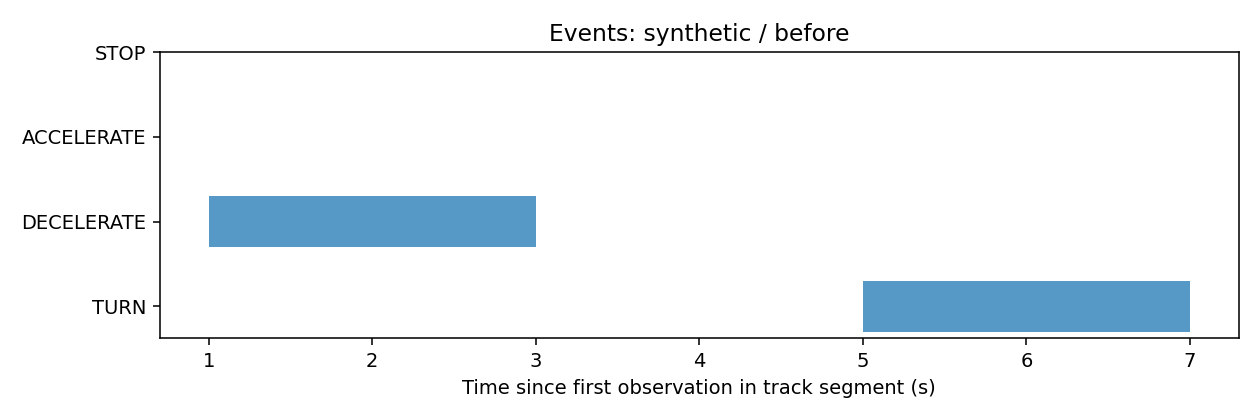

pilot_motion 동등성: True 트랙: 5 사건: 8


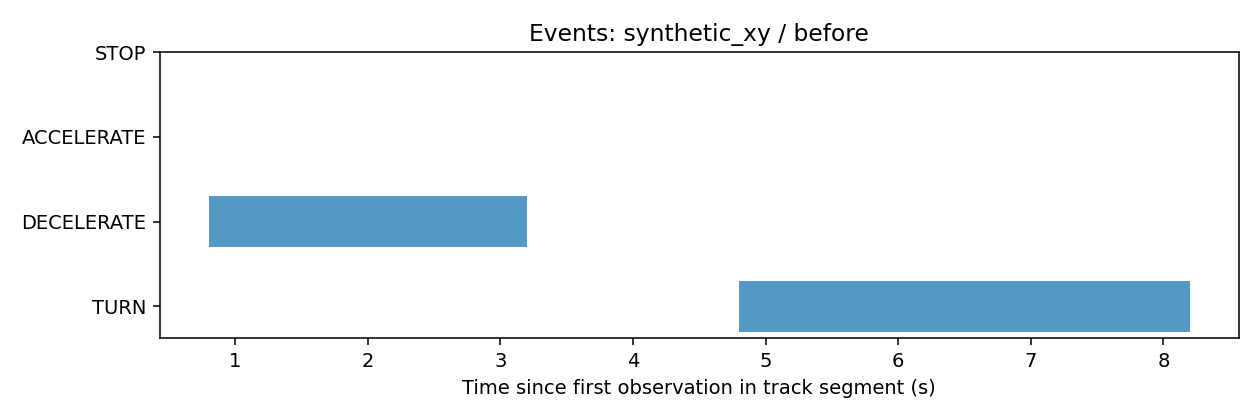

In [5]:
!python teg_pilot.py --out pilot_synthetic --repeat 200
!python teg_pilot.py --demo-detector --out pilot_motion --repeat 200

import json
from pathlib import Path
from IPython.display import display, Image
for folder in ("pilot_synthetic", "pilot_motion"):
    info=json.loads((Path(folder)/"pilot_report.json").read_text())
    print(folder, "동등성:", info["all_query_results_equal"],
          "트랙:",info["track_count"], "사건:",info["event_count"])
    if (Path(folder)/"events_preview.png").exists():
        display(Image(filename=str(Path(folder)/"events_preview.png")))


## B. 질의 검색 시간 실험 (합성 1,000개 트랙)

실제 주행 로그와 무관한 **복제된 합성 사건 패턴**을 이용하여 실행기별 평균 지연시간을 비교합니다. 그래프 구축비용은 별도로 보고되며 실제 AV2의 실행시간으로 인용해서는 안 됩니다.


In [6]:
!python teg_pilot.py --demo-scale 1000 --out pilot_scale1000 --repeat 30
import pandas as pd
from pathlib import Path
import json
r=json.loads(Path("pilot_scale1000/pilot_report.json").read_text())
display(pd.DataFrame([{
 "방식":"Interval", "평균 질의시간(ms)":r["mean_interval_query_ms"]},
 {"방식":"Graph", "평균 질의시간(ms)":r["mean_graph_query_ms"]}]))
print("그래프 구축시간(ms):",r["graph_build_ms"])
print("추정 손익분기 질의 수:",r["estimated_break_even_query_count"])
print("전 질의 검색 동등성:",r["all_query_results_equal"])


Data: synthetic_scaled_stress_test_NOT_AV2 | tracks=1000 events=1833
Graph edges=666 | equality=True
Graph build: 21.150 ms | query means (ms): interval=0.98182 graph=0.39973
  DECELERATE THEN TURN                     {'NEGATIVE': 500, 'POSITIVE': 167, 'UNCERTAIN': 167, 'PARTIAL': 166} equal=True
  TURN THEN DECELERATE                     {'POSITIVE': 167, 'NEGATIVE': 500, 'UNCERTAIN': 167, 'PARTIAL': 166} equal=True
  DECELERATE WHILE TURN                    {'NEGATIVE': 501, 'UNCERTAIN': 167, 'PARTIAL': 166, 'POSITIVE': 166} equal=True
  TURN WHILE DECELERATE                    {'NEGATIVE': 501, 'UNCERTAIN': 167, 'PARTIAL': 166, 'POSITIVE': 166} equal=True
  DECELERATE THEN STOP                     {'NEGATIVE': 1000} equal=True
  STOP THEN DECELERATE                     {'NEGATIVE': 1000} equal=True
  DECELERATE THEN ACCELERATE               {'NEGATIVE': 1000} equal=True
  ACCELERATE THEN DECELERATE               {'NEGATIVE': 1000} equal=True
  ACCELERATE WHILE TURN                  

,방식,평균 질의시간(ms)
0,Interval,0.98182
1,Graph,0.39973


그래프 구축시간(ms): 21.15
추정 손익분기 질의 수: 36
전 질의 검색 동등성: True


## C. 실제 Argoverse 2 로그 읽기 (사용자가 자료를 준비한 뒤)

1. AV2 Sensor Dataset의 각 로그 폴더에서 `annotations.feather`와 `city_SE3_egovehicle.feather`를 준비합니다.
2. Google Drive에 `AV2_subset/<log_id>/` 형태로 올립니다.
3. 아래의 `RUN_REAL_AV2=True`를 설정하고 `AV2_ROOT`를 수정합니다.
4. 처음에는 `--max-logs 2` 또는 3으로 소량 확인합니다.

AV2 어노테이션은 egovehicle 좌표계, pose는 city 좌표 변환이므로 코드에서 회전+이동을 적용합니다. 최근접 pose 시간 차이는 보고서에 기록하며 기본 15ms보다 큰 차이는 무조건 무시하지 않습니다.

공식 필드 설명: https://argoverse.github.io/user-guide/datasets/sensor.html


In [7]:
RUN_REAL_AV2 = False
AV2_ROOT = "/content/drive/MyDrive/AV2_subset"  # 본인의 Drive 경로로 수정

if RUN_REAL_AV2:
    from google.colab import drive
    drive.mount('/content/drive')
    import subprocess
    result = subprocess.run([
        "python", "teg_pilot.py", "--av2-root", AV2_ROOT,
        "--max-logs", "3", "--repeat", "30", "--out", "pilot_real_av2"
    ], check=True)
    report=json.loads(Path("pilot_real_av2/pilot_report.json").read_text())
    print("동등성:", report["all_query_results_equal"])
    print("로그별 진단:")
    display(pd.DataFrame(report["av2_log_diagnostics"]))
else:
    print("실제 AV2 실험은 실행하지 않았습니다. 두 Feather 파일을 준비한 뒤 RUN_REAL_AV2=True로 변경하세요.")


실제 AV2 실험은 실행하지 않았습니다. 두 Feather 파일을 준비한 뒤 RUN_REAL_AV2=True로 변경하세요.


## D. 판정 기준

- `all_query_results_equal`이 `False`이면 그래프 백엔드에 오류가 있으므로 시간을 비교하기 전에 수정합니다.
- `PARTIAL` 및 `UNCERTAIN`은 `NEGATIVE`로 간주하지 않습니다.
- 이벤트가 검출되지 않은 평가 가능 트랙 역시 검색 모집단에 포함해야 합니다.
- 그래프 조회시간의 감소만으로 시스템 전체 효율이 높다고 주장하지 않습니다. 그래프 생성과 인덱스 보관비용을 포함해야 합니다.
- 다음 단계는 **실제 AV2 로그 2~3개에서 사건별 분포 및 궤적 그래프를 검수**하고, 이후 B2와 P에서 생성한 계획을 같은 실행기로 평가하는 것입니다.
